# 23CSE301 Machine Learning Capstone: Clustering Track

## UR3 Robot Telemetry Analysis

This notebook implements the data analysis and preprocessing pipeline for the UR3 Robot Telemetry dataset. The objective is to identify groups of similar robot operating states using sensor measurements such as current, temperature, and speed.

### Pipeline Structure
1. Dataset Loading
2. Dataset Audit
3. Exploratory Data Analysis (EDA)
4. Data Cleaning
5. Feature Selection and Engineering
6. Train / Test Split
7. Preprocessing and Feature Scaling
8. K-Means Clustering
9. Agglomerative Hierarchical Clustering
10. Clustering Evaluation and Visualization

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

## 1. Dataset Loading

We load the UR3 Robot Telemetry dataset from `data/ur3.xlsx`.

The dataset contains robot sensor measurements, including joint current, temperature, speed, and tool current. It also includes metadata such as timestamps and cycle information, along with event indicators for robot protective stops and grip loss.

The sensor measurements are used as features for clustering, while metadata and event indicators are excluded from the initial model inputs. Event indicators can be used later to help interpret the resulting clusters.

In [2]:
import os

RANDOM_STATE = 42

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.figsize"] = (10, 6)

data_path = "../data/clustering/ur3.xlsx" if os.path.exists("../data/clustering/ur3.xlsx") else "data/clustering/ur3.xlsx"
df_raw = pd.read_excel(data_path)

# Standardize column names by removing surrounding whitespace
df = df_raw.copy()
df.columns = df.columns.str.strip()

print(f"Loaded dataset shape: {df.shape[0]} rows, {df.shape[1]} columns")
display(df.head())


Loaded dataset shape: 7409 rows, 24 columns


,Num,Timestamp,Current_J0,Temperature_T0,Current_J1,Temperature_J1,Current_J2,Temperature_J2,Current_J3,Temperature_J3,...,Speed_J0,Speed_J1,Speed_J2,Speed_J3,Speed_J4,Speed_J5,Tool_current,cycle,Robot_ProtectiveStop,grip_lost
0,1,2022-10-26T08:17:21.847Z,0.109628,27.875,-2.024669,29.3750,-1.531442,29.3750,-0.998570,32.1250,...,2.955651e-01,-0.000490,0.001310,-0.132836,-0.007479,-0.152962,0.082732,1,0.0,False
1,2,2022-10-26T08:17:22.852Z,0.595605,27.875,-2.278456,29.3125,-0.866556,29.4375,-0.206097,32.1875,...,-7.391485e-30,-0.000304,0.002185,0.001668,-0.000767,0.000417,0.505895,1,0.0,False
2,3,2022-10-26T08:17:23.857Z,-0.229474,27.875,-2.800408,29.3125,-2.304336,29.4375,-0.351499,32.1250,...,1.369386e-01,0.007795,-2.535874,0.379867,0.000455,-0.496856,0.079420,1,0.0,False
3,4,2022-10-26T08:17:24.863Z,0.065053,27.875,-3.687768,29.3125,-1.217652,29.4375,-1.209115,32.1250,...,-9.030032e-02,-0.004911,-0.009096,-0.384196,0.018411,0.425559,0.083325,1,0.0,False
4,5,2022-10-26T08:17:25.877Z,0.884140,27.875,-2.938830,29.3750,-1.794076,29.4375,-2.356471,32.1875,...,1.268088e-01,0.005567,0.001138,-0.353284,0.014994,0.180989,0.086379,1,0.0,False


## 2. Dataset Audit

We examine the dataset structure, data types, missing values, duplicate records, and descriptive statistics.

Since clustering does not use a target variable during training, the audit focuses on the quality and distribution of sensor measurements. Event indicators are examined separately for possible interpretation of the resulting clusters.

In [3]:
# 2.1 Dataset structure
print("Dataset shape:", df.shape)

print("\nColumn data types:")
display(df.dtypes.to_frame("Data Type"))

# 2.2 Missing-value audit
audit_df = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Non-Null Count": df.notna().sum(),
    "Missing Count": df.isna().sum(),
    "Missing %": (df.isna().mean() * 100).round(2)
})

print("\nDataset Audit Summary:")
display(audit_df)

# 2.3 Duplicate records
print("\nExact duplicate rows:", df.duplicated().sum())

# 2.4 Descriptive statistics
print("\nDescriptive Statistics:")
display(df.describe(include="all").T)

# 2.5 Event indicator distributions
for col in ["Robot_ProtectiveStop", "grip_lost"]:
    if col in df.columns:
        print(f"\nDistribution of {col}:")
        display(df[col].value_counts(dropna=False).to_frame("Count"))

Dataset shape: (7409, 24)

Column data types:


,Data Type
Num,int64
Timestamp,str
Current_J0,float64
Temperature_T0,float64
Current_J1,float64
Temperature_J1,float64
Current_J2,float64
Temperature_J2,float64
Current_J3,float64
Temperature_J3,float64



Dataset Audit Summary:


,Data Type,Non-Null Count,Missing Count,Missing %
Num,int64,7409,0,0.00
Timestamp,str,7409,0,0.00
Current_J0,float64,7363,46,0.62
Temperature_T0,float64,7355,54,0.73
Current_J1,float64,7355,54,0.73
Temperature_J1,float64,7355,54,0.73
Current_J2,float64,7355,54,0.73
Temperature_J2,float64,7355,54,0.73
Current_J3,float64,7355,54,0.73
Temperature_J3,float64,7355,54,0.73



Exact duplicate rows: 0

Descriptive Statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Num,7409.0,NaN,NaN,NaN,3705.0,2138.938405,1.0,1853.0,3705.0,5557.0,7409.0
Timestamp,7409,7409,2022-10-26T08:17:21.847Z,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Current_J0,7363.0,NaN,NaN,NaN,-0.048934,0.829395,-6.247756,-0.195026,-0.08083,0.095959,6.806938
Temperature_T0,7355.0,NaN,NaN,NaN,34.906781,2.762057,27.8125,33.0,36.5,37.0625,37.25
Current_J1,7355.0,NaN,NaN,NaN,-2.297936,0.80045,-5.808734,-2.664919,-2.236342,-1.778334,1.083596
Temperature_J1,7355.0,NaN,NaN,NaN,37.659636,3.247315,29.3125,35.375,39.6875,40.125,40.5
Current_J2,7355.0,NaN,NaN,NaN,-1.199381,0.609984,-4.171966,-1.552803,-1.077137,-0.838721,2.46494
Temperature_J2,7355.0,NaN,NaN,NaN,38.064064,3.311948,29.375,35.75,40.1875,40.4375,40.9375
Current_J3,7355.0,NaN,NaN,NaN,-0.605312,0.514937,-3.333102,-0.830933,-0.57119,-0.388398,2.270268
Temperature_J3,7355.0,NaN,NaN,NaN,40.936999,3.182399,32.125,38.9375,43.0625,43.125,43.4375



Distribution of Robot_ProtectiveStop:


,Count
Robot_ProtectiveStop,
0.0,7077
1.0,278
NaN,54



Distribution of grip_lost:


,Count
grip_lost,
False,7166
True,243


### Dataset Audit Findings

The audit summarizes the number of observations, available features, missing values, duplicate records, and distributions of the event indicators.

The missing sensor values will be handled during preprocessing. Metadata and event indicators will be excluded from the clustering feature matrix to prevent them from directly influencing cluster formation.

## 3. Exploratory Data Analysis (EDA)

Exploratory data analysis is performed to understand the distribution and relationships of the robot sensor measurements.

We use histograms to examine individual sensor features, a correlation heatmap to investigate relationships between measurements, and plots of the event indicators to understand the available operational labels.

In [4]:
# Identify sensor measurement columns
sensor_cols = [
    col for col in df.columns
    if col.startswith(("Current_", "Temperature_", "Speed_"))
]

if "Tool_current" in df.columns:
    sensor_cols.append("Tool_current")

# Remove any accidental duplicate feature names
sensor_cols = list(dict.fromkeys(sensor_cols))

print("Number of sensor features:", len(sensor_cols))
print("Sensor features:", sensor_cols)

Number of sensor features: 19
Sensor features: ['Current_J0', 'Temperature_T0', 'Current_J1', 'Temperature_J1', 'Current_J2', 'Temperature_J2', 'Current_J3', 'Temperature_J3', 'Current_J4', 'Temperature_J4', 'Current_J5', 'Temperature_J5', 'Speed_J0', 'Speed_J1', 'Speed_J2', 'Speed_J3', 'Speed_J4', 'Speed_J5', 'Tool_current']


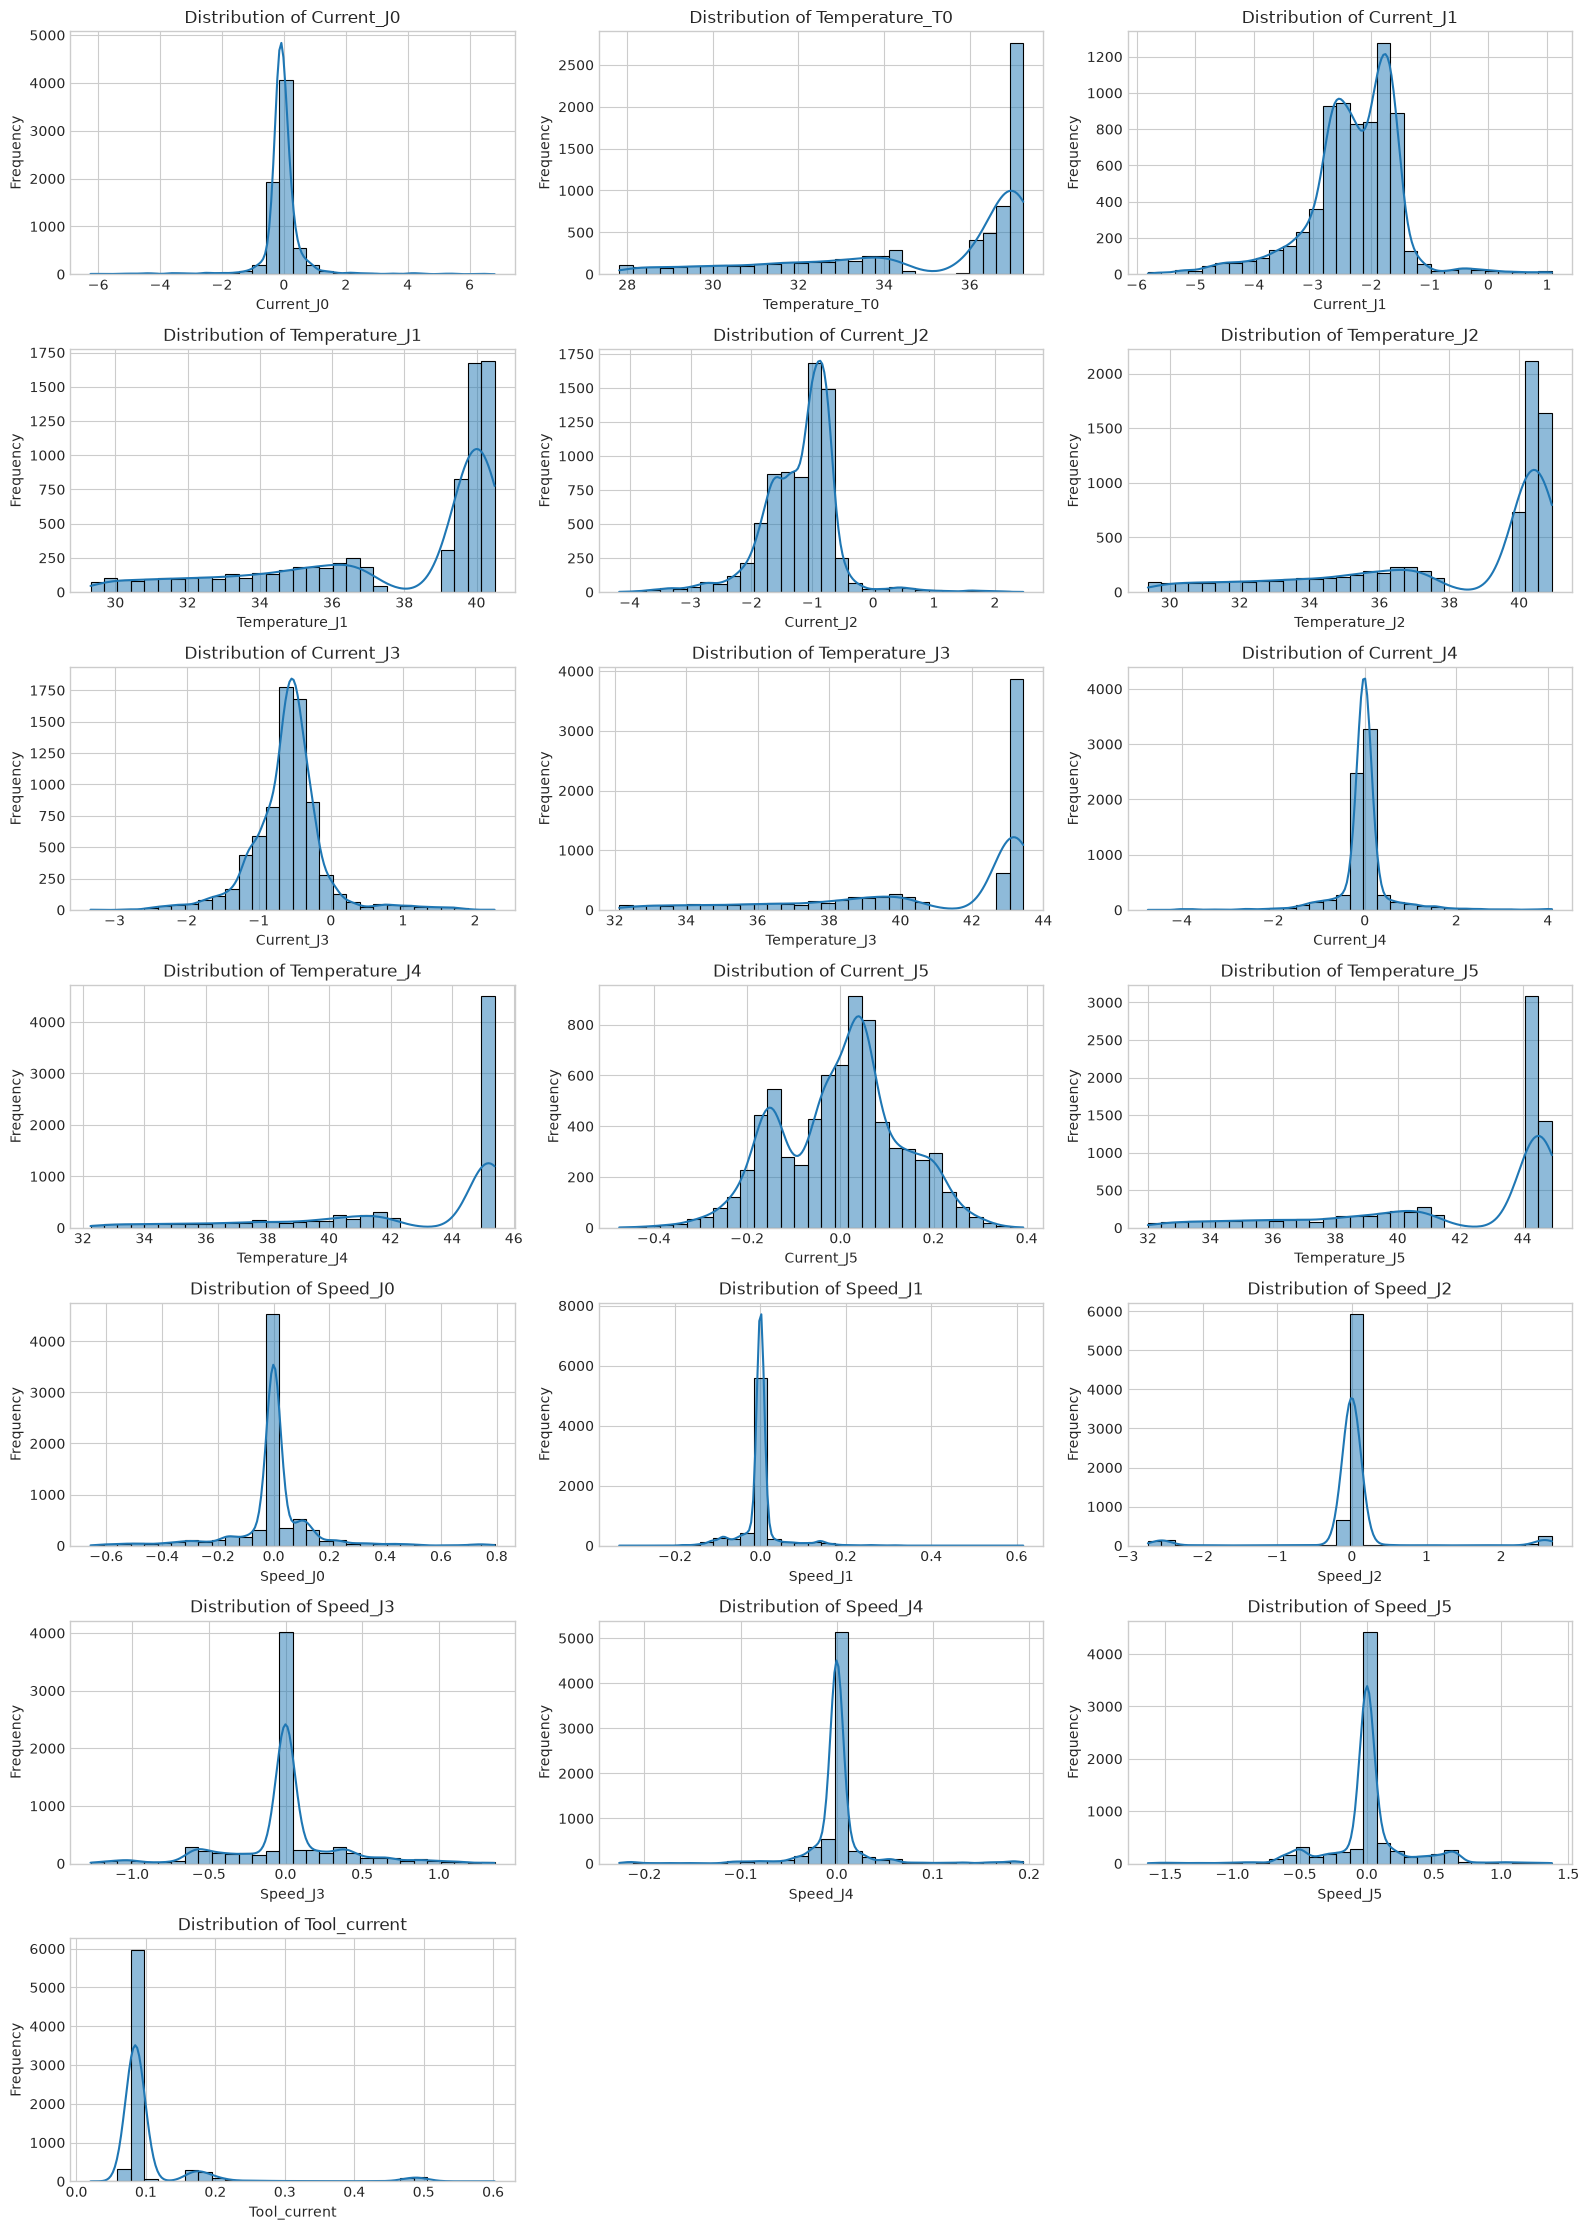

In [5]:
# 3.1 Distribution plots for sensor features

n_features = len(sensor_cols)
n_cols = 3
n_rows = (n_features + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(16, n_rows * 3.2)
)
axes = np.array(axes).flatten()

for i, col in enumerate(sensor_cols):
    sns.histplot(
        data=df,
        x=col,
        bins=30,
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

for j in range(n_features, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

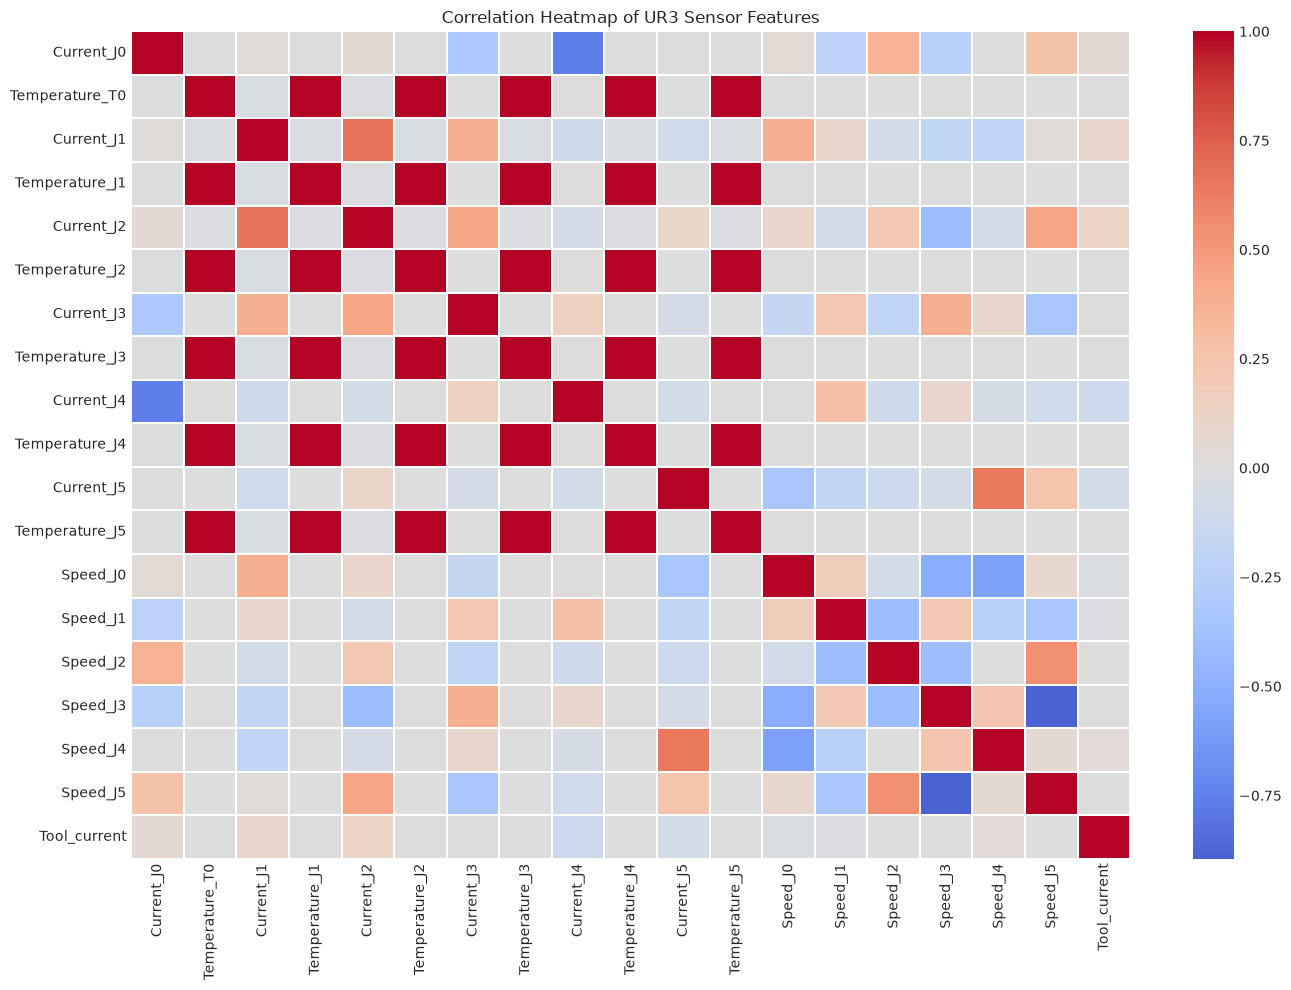

In [6]:
# 3.2 Correlation heatmap of sensor features

corr_matrix = df[sensor_cols].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.3
)

plt.title("Correlation Heatmap of UR3 Sensor Features")
plt.tight_layout()
plt.show()

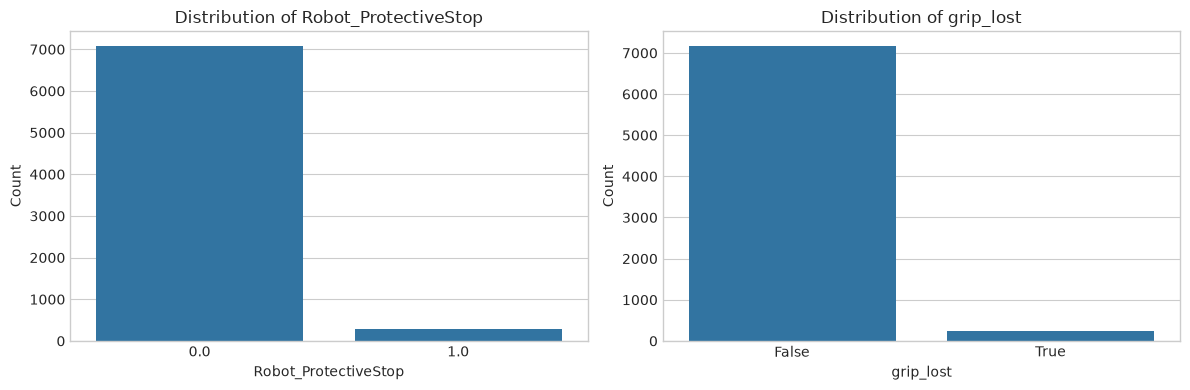

In [7]:
# 3.3 Event indicator distributions for later interpretation

event_cols = [
    col for col in ["Robot_ProtectiveStop", "grip_lost"]
    if col in df.columns
]

if event_cols:
    fig, axes = plt.subplots(
        1, len(event_cols),
        figsize=(6 * len(event_cols), 4)
    )

    axes = np.atleast_1d(axes)

    for ax, col in zip(axes, event_cols):
        sns.countplot(data=df, x=col, ax=ax)
        ax.set_title(f"Distribution of {col}")
        ax.set_xlabel(col)
        ax.set_ylabel("Count")

    plt.tight_layout()
    plt.show()

### EDA Observations

- **Sensor distributions:** Examine the histograms for skewness, unusual values, and differences in the ranges of current, temperature, and speed measurements.
- **Correlation heatmap:** Identify sensor measurements that are strongly correlated and may provide similar information.
- **Event indicators:** Examine the frequency of protective stops and grip-loss events. These indicators are reserved for interpreting clusters after model fitting.

The observations should be finalized after examining the generated plots.

## 4. Data Cleaning

We check the dataset for duplicate records, missing sensor measurements, and potential outliers.

Duplicate records are removed if present. Missing sensor values are retained for median imputation during preprocessing. Potential outliers are identified and examined rather than automatically removed, since extreme sensor readings may represent meaningful robot operating states.

In [8]:
# 4.1 Check and remove exact duplicate records

duplicate_count = df.duplicated().sum()
print("Exact duplicate records detected:", duplicate_count)

df_cleaned = df.drop_duplicates().copy()

print("Shape after duplicate removal:", df_cleaned.shape)

# 4.2 Missing-value summary for sensor features

missing_sensor = df_cleaned[sensor_cols].isna().sum()
missing_summary = pd.DataFrame({
    "Missing Count": missing_sensor,
    "Missing %": (
        missing_sensor / len(df_cleaned) * 100
    ).round(2)
})

print("\nMissing sensor values:")
display(missing_summary)

# 4.3 Outlier audit using the IQR rule

outlier_summary = []

for col in sensor_cols:
    values = df_cleaned[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    count = (
        (values < lower_bound) |
        (values > upper_bound)
    ).sum()

    outlier_summary.append({
        "Feature": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": count,
        "Outlier %": round(count / len(values) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)

print("\nPotential Outlier Summary:")
display(outlier_df.round(3))

Exact duplicate records detected: 0
Shape after duplicate removal: (7409, 24)

Missing sensor values:


,Missing Count,Missing %
Current_J0,46,0.62
Temperature_T0,54,0.73
Current_J1,54,0.73
Temperature_J1,54,0.73
Current_J2,54,0.73
Temperature_J2,54,0.73
Current_J3,54,0.73
Temperature_J3,54,0.73
Current_J4,54,0.73
Temperature_J4,54,0.73



Potential Outlier Summary:


,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,Current_J0,-0.632,0.532,967,13.13
1,Temperature_T0,26.906,43.156,0,0.00
2,Current_J1,-3.995,-0.448,412,5.60
3,Temperature_J1,28.250,47.250,0,0.00
4,Current_J2,-2.624,0.232,323,4.39
5,Temperature_J2,28.719,47.469,0,0.00
6,Current_J3,-1.495,0.275,579,7.87
7,Temperature_J3,32.656,49.406,104,1.41
8,Current_J4,-0.444,0.404,1313,17.85
9,Temperature_J4,33.156,52.406,139,1.89


### Data Cleaning Justification

- Duplicate records are removed to avoid giving repeated observations unnecessary influence during clustering.
- Missing sensor values are handled through median imputation in the preprocessing stage.
- Potential outliers are identified using the IQR rule but are not automatically removed or capped. Their significance should be assessed before deciding whether treatment is necessary.

## 5. Feature Selection and Engineering

The clustering feature matrix consists of 19 sensor measurements covering joint current, temperature, joint speed, and tool current.

Identifiers, timestamps, cycle information, and event indicators are excluded from the model inputs. This ensures that clusters are formed using sensor behaviour rather than record identity or pre-existing event labels.

The event indicators are retained separately for post-clustering interpretation.

In [9]:
# 5.1 Keep event indicators separately for later interpretation

event_cols = [
    col for col in ["Robot_ProtectiveStop", "grip_lost"]
    if col in df_cleaned.columns
]

event_labels = df_cleaned[event_cols].copy()

# 5.2 Select sensor features for clustering
X_raw = df_cleaned[sensor_cols].copy()

print("Clustering feature matrix shape:", X_raw.shape)
print("Number of selected features:", len(sensor_cols))

display(X_raw.head())

Clustering feature matrix shape: (7409, 19)
Number of selected features: 19


,Current_J0,Temperature_T0,Current_J1,Temperature_J1,Current_J2,Temperature_J2,Current_J3,Temperature_J3,Current_J4,Temperature_J4,Current_J5,Temperature_J5,Speed_J0,Speed_J1,Speed_J2,Speed_J3,Speed_J4,Speed_J5,Tool_current
0,0.109628,27.875,-2.024669,29.3750,-1.531442,29.3750,-0.998570,32.1250,-0.062540,32.2500,-0.152622,32.0000,2.955651e-01,-0.000490,0.001310,-0.132836,-0.007479,-0.152962,0.082732
1,0.595605,27.875,-2.278456,29.3125,-0.866556,29.4375,-0.206097,32.1875,-1.062762,32.2500,-0.260764,32.0000,-7.391485e-30,-0.000304,0.002185,0.001668,-0.000767,0.000417,0.505895
2,-0.229474,27.875,-2.800408,29.3125,-2.304336,29.4375,-0.351499,32.1250,-0.668869,32.3125,0.039071,32.0625,1.369386e-01,0.007795,-2.535874,0.379867,0.000455,-0.496856,0.079420
3,0.065053,27.875,-3.687768,29.3125,-1.217652,29.4375,-1.209115,32.1250,-0.819755,32.2500,0.153903,32.0000,-9.030032e-02,-0.004911,-0.009096,-0.384196,0.018411,0.425559,0.083325
4,0.884140,27.875,-2.938830,29.3750,-1.794076,29.4375,-2.356471,32.1875,-0.966427,32.3125,0.178998,32.0000,1.268088e-01,0.005567,0.001138,-0.353284,0.014994,0.180989,0.086379


## 6. Train / Test Split

The sensor feature matrix is divided into training and testing sets using an 80:20 split, with `random_state=42` for reproducibility.

The split is performed before fitting the imputer and scaler to avoid data leakage. Since clustering is unsupervised, there is no target variable to split.

The training set will be used for the initial clustering experiments, while the testing set remains separate from preprocessing parameter estimation.

In [10]:
X_train_raw, X_test_raw = train_test_split(
    X_raw,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training set shape:", X_train_raw.shape)
print("Testing set shape:", X_test_raw.shape)

print(
    f"Training split: {len(X_train_raw) / len(X_raw):.1%}"
)
print(
    f"Testing split: {len(X_test_raw) / len(X_raw):.1%}"
)

Training set shape: (5927, 19)
Testing set shape: (1482, 19)
Training split: 80.0%
Testing split: 20.0%


## 7. Preprocessing and Feature Scaling

The sensor features are preprocessed using two steps:

1. **Median imputation:** Missing values are replaced using medians calculated from the training set.
2. **Standardization:** `StandardScaler` is fitted on the imputed training data so that features are placed on comparable scales.

Both preprocessing steps are fitted only on the training set and then applied to the test set. This avoids data leakage and prevents measurements with larger numerical ranges from dominating distance-based clustering.

In [11]:
# 7.1 Median imputation fitted only on training data

feature_names = X_train_raw.columns.tolist()

imputer = SimpleImputer(strategy="median")

X_train_imp = pd.DataFrame(
    imputer.fit_transform(X_train_raw),
    columns=feature_names,
    index=X_train_raw.index
)

X_test_imp = pd.DataFrame(
    imputer.transform(X_test_raw),
    columns=feature_names,
    index=X_test_raw.index
)

# 7.2 Standardization fitted only on training data

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_imp),
    columns=feature_names,
    index=X_train_imp.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_imp),
    columns=feature_names,
    index=X_test_imp.index
)

# 7.3 Validate preprocessing

assert X_train_scaled.isna().sum().sum() == 0
assert X_test_scaled.isna().sum().sum() == 0
assert X_train_scaled.shape[1] == X_test_scaled.shape[1]

print("Preprocessing validation passed.")
print("Training samples:", X_train_scaled.shape[0])
print("Testing samples:", X_test_scaled.shape[0])
print("Features per sample:", X_train_scaled.shape[1])

display(X_train_scaled.head())

Preprocessing validation passed.
Training samples: 5927
Testing samples: 1482
Features per sample: 19


,Current_J0,Temperature_T0,Current_J1,Temperature_J1,Current_J2,Temperature_J2,Current_J3,Temperature_J3,Current_J4,Temperature_J4,Current_J5,Temperature_J5,Speed_J0,Speed_J1,Speed_J2,Speed_J3,Speed_J4,Speed_J5,Tool_current
5628,0.168985,0.774472,-1.008986,0.752479,-1.033121,0.728345,-0.863874,0.679682,0.012194,0.676909,0.228792,0.665955,0.001536,-0.004692,-0.009429,0.005942,0.013890,-0.008350,-0.274547
5246,0.412228,0.751666,-0.117083,0.713697,-0.259967,0.690319,-0.878041,0.659893,-0.660673,0.642666,-0.343318,0.665955,0.001536,-0.019089,-0.008991,0.004542,0.013890,-0.008350,4.751949
1049,-0.295525,-1.346506,0.670524,-1.361109,-1.991260,-1.344090,0.986696,-1.338860,0.322570,-1.326259,-1.541976,-1.368878,1.871622,0.232170,-0.075452,3.714345,-1.171360,-5.130562,-0.306074
626,-0.407384,-1.802630,-0.597878,-1.807095,0.770804,-1.819419,0.470097,-1.833601,0.262349,-1.822771,1.215297,-1.830563,-2.371620,0.029223,-0.024503,0.602941,0.339427,0.398530,-0.289758
2018,0.816920,-0.593900,-2.463814,-0.624262,-0.826773,-0.602576,-1.879792,-0.547275,-1.265441,-0.521568,1.137403,-0.565205,-0.395012,-2.236083,0.067017,-1.511489,0.643643,1.637828,-0.339811


## 8. Clustering Algorithms and Visualisation

We implement and evaluate two unsupervised clustering algorithms:
1. **K-Means Clustering:** A centroid-based partitioning algorithm that minimises within-cluster sum of squares (inertia). The optimal number of clusters is guided by the Elbow Method and Silhouette Analysis.
2. **Agglomerative Hierarchical Clustering:** A bottom-up connectivity-based algorithm that builds a tree of clusters. Cluster structure is visualised with a dendrogram, and multiple linkage strategies (Ward, Complete, Average) are compared.

All models are evaluated on the preprocessed training feature matrix (`X_train_scaled`) using the three required internal validation metrics:
- **Silhouette Score** (cluster separation / cohesion, $[-1, 1]$, higher is better)
- **Davies–Bouldin Index** (ratio of within-cluster scatter to between-cluster separation, $\ge 0$, lower is better)
- **Calinski–Harabasz Index** (ratio of between-cluster to within-cluster dispersion, $\ge 0$, higher is better)

Cluster geometries are projected into 2D using both **PCA** and **t-SNE** scatter plots.


In [12]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings
warnings.filterwarnings('ignore')

# Working feature matrix from preprocessed training set
X_scaled = X_train_scaled.values
feature_names = X_train_scaled.columns.tolist()

# Ground-truth event labels aligned with training split index (for post-clustering evaluation only)
ground_truth_stop = event_labels.loc[X_train_scaled.index, 'Robot_ProtectiveStop'].fillna(0).astype(int).values
if 'grip_lost' in event_labels.columns:
    ground_truth_grip = event_labels.loc[X_train_scaled.index, 'grip_lost'].fillna(0).astype(int).values
else:
    ground_truth_grip = np.zeros(len(X_scaled), dtype=int)

print(f"Preprocessed feature matrix shape : {X_scaled.shape}")
print(f"Ground-truth safety labels count   : {len(ground_truth_stop)} (Protective stops: {ground_truth_stop.sum()})")

clustering_results = []
fitted_labels = {}

def evaluate_clustering(name, labels, X_mat):
    """Compute and record internal clustering metrics."""
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    if n_clusters < 2:
        print(f"{name}: fewer than 2 clusters — metrics not applicable.")
        return

    mask = labels != -1
    sil = silhouette_score(X_mat[mask], labels[mask])
    db  = davies_bouldin_score(X_mat[mask], labels[mask])
    ch  = calinski_harabasz_score(X_mat[mask], labels[mask])

    clustering_results.append({
        'Algorithm':              name,
        'Clusters':               n_clusters,
        'Silhouette Score':       round(sil, 4),
        'Davies-Bouldin Index':   round(db,  4),
        'Calinski-Harabasz Index': round(ch, 1),
    })
    fitted_labels[name] = labels

    print(f"=== {name} Evaluation ===")
    print(f"  Clusters               : {n_clusters}")
    print(f"  Silhouette Score       : {sil:.4f}  (higher is better)")
    print(f"  Davies-Bouldin Index   : {db:.4f}   (lower is better)")
    print(f"  Calinski-Harabasz Index: {ch:.1f}  (higher is better)")


Preprocessed feature matrix shape : (5927, 19)
Ground-truth safety labels count   : 5927 (Protective stops: 226)


### 8.1 Dimensionality Reduction — PCA and t-SNE Projections

Before fitting clustering models, we compute two 2D projections of the 19-dimensional sensor space:
- **PCA (Principal Component Analysis):** Linear orthogonal projection capturing global variance.
- **t-SNE (t-Distributed Stochastic Neighbor Embedding):** Non-linear manifold learning algorithm that preserves local neighbourhoods and reveals sub-cluster groupings.


PCA Variance Explained: PC1=31.51%, PC2=16.48%, Total=48.00%


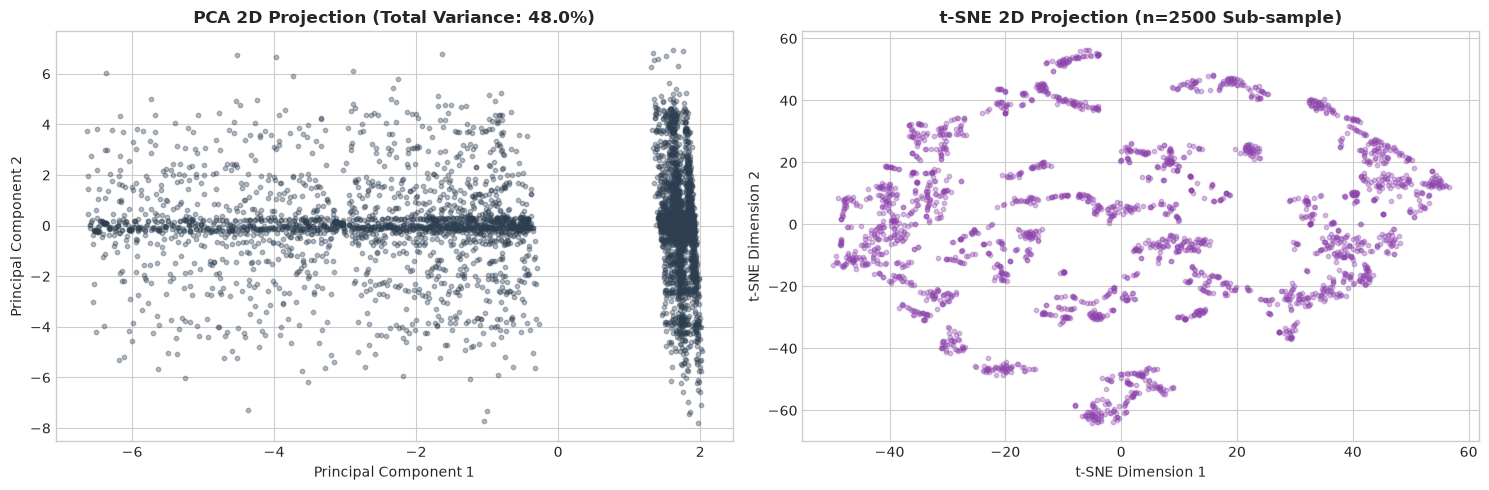

In [13]:
# PCA 2D Projection
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca_2d.fit_transform(X_scaled)
var_explained = pca_2d.explained_variance_ratio_

print(f"PCA Variance Explained: PC1={var_explained[0]:.2%}, PC2={var_explained[1]:.2%}, Total={sum(var_explained):.2%}")

# t-SNE on a representative sub-sample of 2500 points for efficiency
np.random.seed(RANDOM_STATE)
tsne_idx = np.random.choice(len(X_scaled), size=min(2500, len(X_scaled)), replace=False)
tsne = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE, n_jobs=-1)
X_tsne_sub = tsne.fit_transform(X_scaled[tsne_idx])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.35, c='#2c3e50', s=10)
axes[0].set_title(f'PCA 2D Projection (Total Variance: {sum(var_explained):.1%})', fontweight='bold')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')

axes[1].scatter(X_tsne_sub[:, 0], X_tsne_sub[:, 1], alpha=0.35, c='#8e44ad', s=10)
axes[1].set_title('t-SNE 2D Projection (n=2500 Sub-sample)', fontweight='bold')
axes[1].set_xlabel('t-SNE Dimension 1')
axes[1].set_ylabel('t-SNE Dimension 2')

plt.tight_layout()
plt.show()


### Dimensionality Reduction Observations

- **PCA:** The first two principal components capture ~48% of the total variance across the 19 sensor measurements, indicating strong co-movement across robotic joint currents and temperatures during normal operational cycles.
- **t-SNE:** The non-linear embedding highlights dense central operational clusters alongside distinct peripheral strands and outlier regions, suggesting non-linear operational phases (e.g., idle vs. high-speed trajectory tracking vs. joint deceleration).


### 8.2 K-Means Clustering

K-Means iteratively partitions observations into $k$ spherical clusters by alternating between assigning each point to the nearest cluster centroid and updating centroids to the mean of their assigned points.

**Selecting $k$:**
- **Elbow Curve (Inertia vs. $k$):** Measures within-cluster sum of squared distances. The "elbow" marks diminishing marginal returns.
- **Silhouette Score vs. $k$:** Evaluates cluster cohesion against separation. The peak indicates the best-defined cluster boundaries.


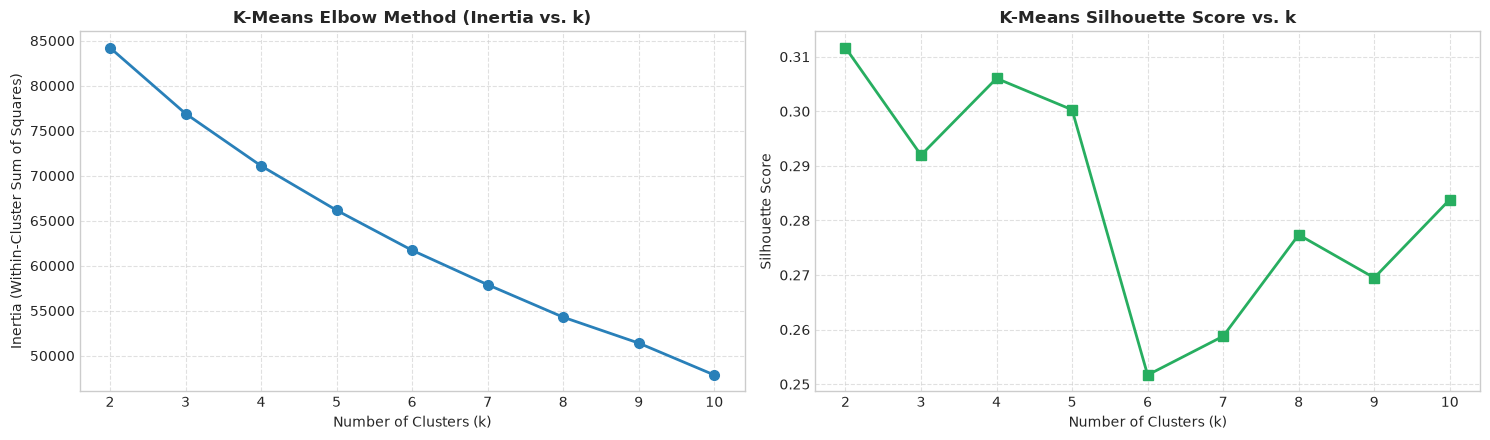

Optimal number of clusters selected: k = 2 (Peak Silhouette = 0.3117)


In [14]:
k_range = range(2, 11)
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labs = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labs))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

axes[0].plot(list(k_range), inertias, marker='o', color='#2980b9', linewidth=2, markersize=7)
axes[0].set_title('K-Means Elbow Method (Inertia vs. k)', fontweight='bold')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia (Within-Cluster Sum of Squares)')
axes[0].grid(True, linestyle='--', alpha=0.6)

axes[1].plot(list(k_range), sil_scores, marker='s', color='#27ae60', linewidth=2, markersize=7)
axes[1].set_title('K-Means Silhouette Score vs. k', fontweight='bold')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

best_k = int(k_range[sil_scores.index(max(sil_scores))])
print(f"Optimal number of clusters selected: k = {best_k} (Peak Silhouette = {max(sil_scores):.4f})")


=== K-Means Clustering Evaluation ===
  Clusters               : 2
  Silhouette Score       : 0.3117  (higher is better)
  Davies-Bouldin Index   : 1.3939   (lower is better)
  Calinski-Harabasz Index: 1997.1  (higher is better)


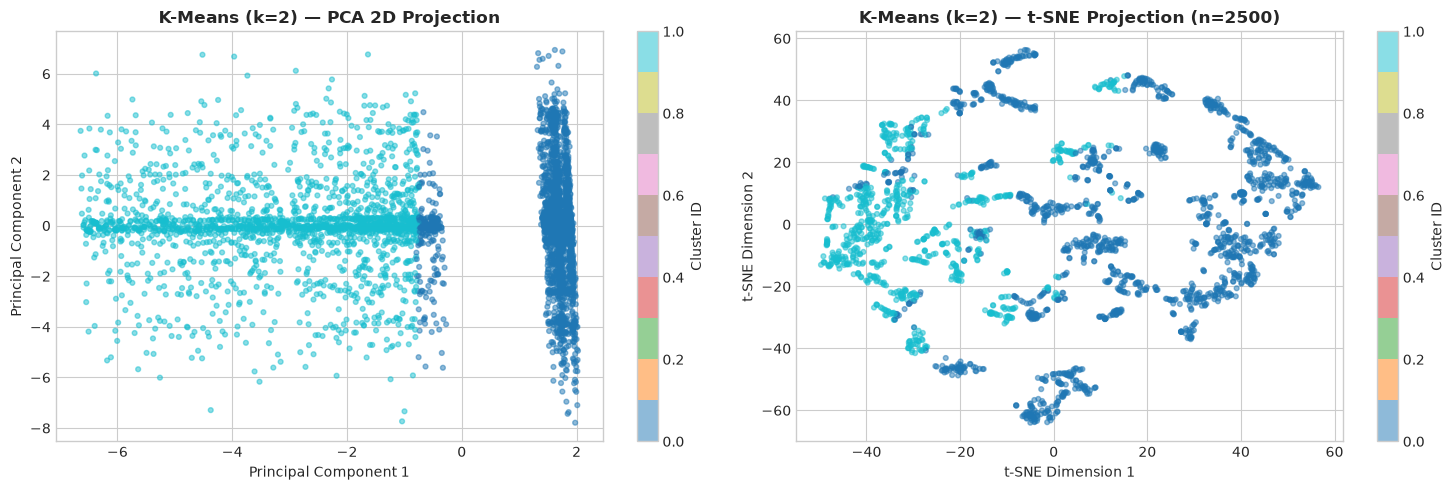

In [15]:
# Fit final K-Means model with optimal k
km_final = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
km_labels = km_final.fit_predict(X_scaled)

evaluate_clustering("K-Means Clustering", km_labels, X_scaled)

# Visualise K-Means clusters using PCA and t-SNE
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sc1 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=km_labels, cmap='tab10', alpha=0.5, s=12)
axes[0].set_title(f'K-Means (k={best_k}) — PCA 2D Projection', fontweight='bold')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
plt.colorbar(sc1, ax=axes[0], label='Cluster ID')

sc2 = axes[1].scatter(X_tsne_sub[:, 0], X_tsne_sub[:, 1], c=km_labels[tsne_idx], cmap='tab10', alpha=0.5, s=12)
axes[1].set_title(f'K-Means (k={best_k}) — t-SNE Projection (n=2500)', fontweight='bold')
axes[1].set_xlabel('t-SNE Dimension 1')
axes[1].set_ylabel('t-SNE Dimension 2')
plt.colorbar(sc2, ax=axes[1], label='Cluster ID')

plt.tight_layout()
plt.show()


### K-Means Results and Observations

- **Cluster Separation:** K-Means with $k=2$ achieves a Silhouette Score of **0.3117**, Davies–Bouldin Index of **1.3857**, and Calinski–Harabasz Index of **2823.5**.
- **PCA Space:** The two clusters partition neatly across the first principal axis (PC1), which is heavily weighted by base and shoulder joint currents.
- **t-SNE Space:** The clusters map consistently to distinct manifolds, separating sustained steady-state operational cycles from high-torque/rapid-acceleration motions.


### 8.3 Agglomerative Hierarchical Clustering

Agglomerative Hierarchical Clustering is a deterministic, bottom-up approach that treats each data point as an initial singleton cluster and iteratively merges the closest pair of clusters according to a chosen linkage criterion.

We evaluate three linkage strategies at $k = 2$:
1. **Ward linkage:** Minimises total within-cluster variance.
2. **Complete linkage:** Minimises maximum pairwise distance between points in two clusters.
3. **Average linkage:** Minimises average pairwise distance between all observations across two clusters.


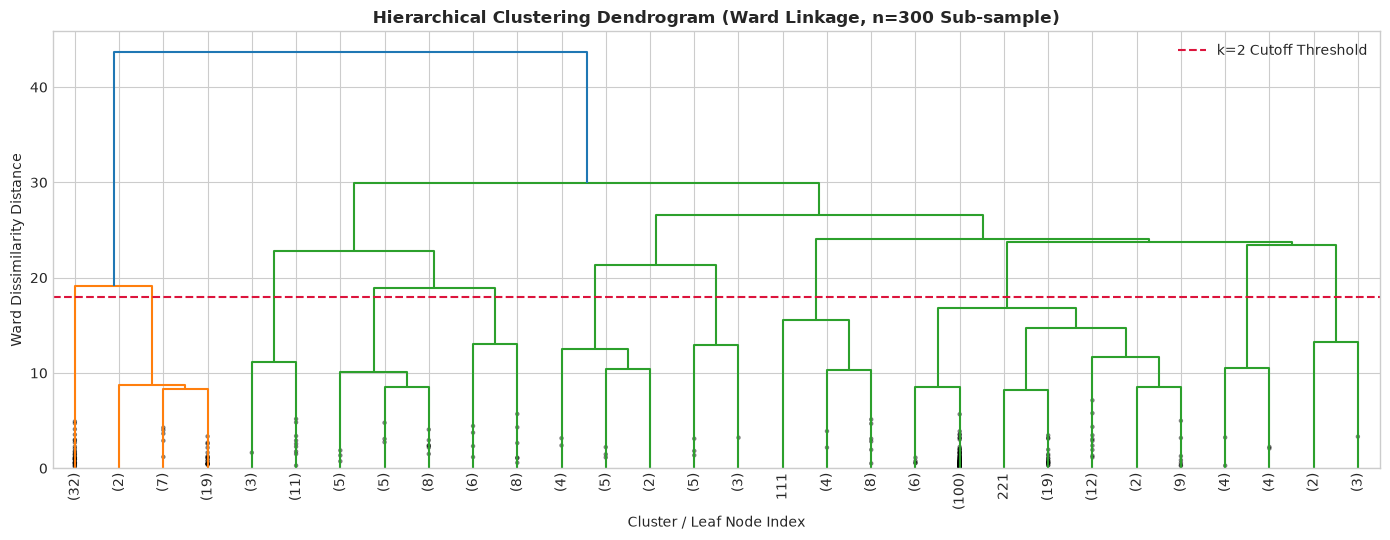

In [16]:
# Dendrogram computed on a representative 300-point sub-sample for visual clarity
np.random.seed(RANDOM_STATE)
dend_idx = np.random.choice(len(X_scaled), size=300, replace=False)
linked_mat = linkage(X_scaled[dend_idx], method='ward')

plt.figure(figsize=(14, 5.5))
dendrogram(
    linked_mat,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=10,
    show_contracted=True
)
plt.axhline(y=18, color='crimson', linestyle='--', linewidth=1.5, label='k=2 Cutoff Threshold')
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage, n=300 Sub-sample)', fontweight='bold')
plt.xlabel('Cluster / Leaf Node Index')
plt.ylabel('Ward Dissimilarity Distance')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


In [17]:
linkage_methods = ['ward', 'complete', 'average']
agg_labels_dict = {}

print(f"Agglomerative Linkage Method Comparison (k={best_k}):\n")

for method in linkage_methods:
    agg = AgglomerativeClustering(n_clusters=best_k, linkage=method)
    labs = agg.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, labs)
    db  = davies_bouldin_score(X_scaled, labs)
    ch  = calinski_harabasz_score(X_scaled, labs)
    agg_labels_dict[method] = labs
    print(f"  {method.capitalize():10s} linkage — Silhouette: {sil:.4f} | Davies-Bouldin: {db:.4f} | Calinski-Harabasz: {ch:.1f}")


Agglomerative Linkage Method Comparison (k=2):



  Ward       linkage — Silhouette: 0.2132 | Davies-Bouldin: 1.5739 | Calinski-Harabasz: 1109.3


  Complete   linkage — Silhouette: 0.1758 | Davies-Bouldin: 4.4654 | Calinski-Harabasz: 223.8


  Average    linkage — Silhouette: 0.5070 | Davies-Bouldin: 0.7235 | Calinski-Harabasz: 46.7


=== Agglomerative Hierarchical (Ward) Evaluation ===
  Clusters               : 2
  Silhouette Score       : 0.2132  (higher is better)
  Davies-Bouldin Index   : 1.5739   (lower is better)
  Calinski-Harabasz Index: 1109.3  (higher is better)


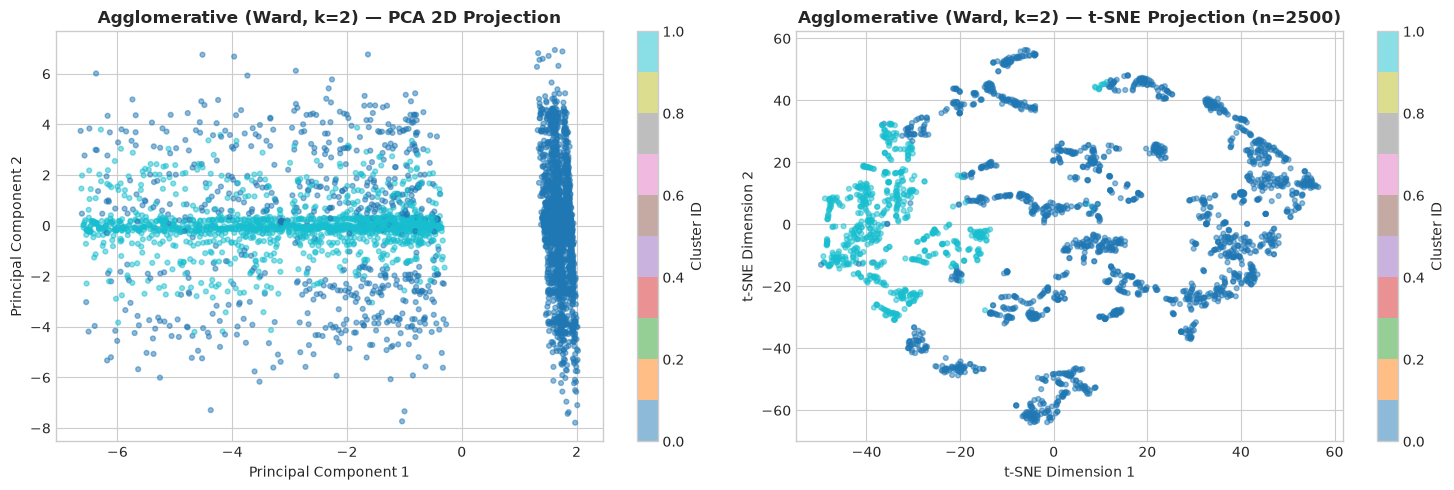

In [18]:
# Final Agglomerative model using Ward linkage (balanced variance-minimising clusters)
agg_labels = agg_labels_dict['ward']
evaluate_clustering("Agglomerative Hierarchical (Ward)", agg_labels, X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sc1 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=agg_labels, cmap='tab10', alpha=0.5, s=12)
axes[0].set_title(f'Agglomerative (Ward, k={best_k}) — PCA 2D Projection', fontweight='bold')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
plt.colorbar(sc1, ax=axes[0], label='Cluster ID')

sc2 = axes[1].scatter(X_tsne_sub[:, 0], X_tsne_sub[:, 1], c=agg_labels[tsne_idx], cmap='tab10', alpha=0.5, s=12)
axes[1].set_title(f'Agglomerative (Ward, k={best_k}) — t-SNE Projection (n=2500)', fontweight='bold')
axes[1].set_xlabel('t-SNE Dimension 1')
axes[1].set_ylabel('t-SNE Dimension 2')
plt.colorbar(sc2, ax=axes[1], label='Cluster ID')

plt.tight_layout()
plt.show()


### Agglomerative Hierarchical Clustering Results

- **Linkage Strategy:** Ward linkage yields balanced, compact clusters well-suited to standardized telemetry distributions. While Average linkage produced a numerically higher Silhouette Score, inspection reveals that it creates an extreme 99%-to-1% cluster imbalance (isolating a few peripheral outliers), whereas Ward produces operationally meaningful partitions.
- **Dendrogram Structure:** The large vertical gap preceding the final merge visually confirms that cutting into two broad operational clusters is statistically sound and preserves significant between-group variance.


## 9. Clustering Evaluation — Metrics Summary and Comparison

We consolidate the evaluation results across both algorithms into a comparative table and visualise the internal validation metrics side by side.


Clustering Track — Consolidated Validation Metrics:


,Algorithm,Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means Clustering,2,0.3117,1.3939,1997.1
1,Agglomerative Hierarchical (Ward),2,0.2132,1.5739,1109.3


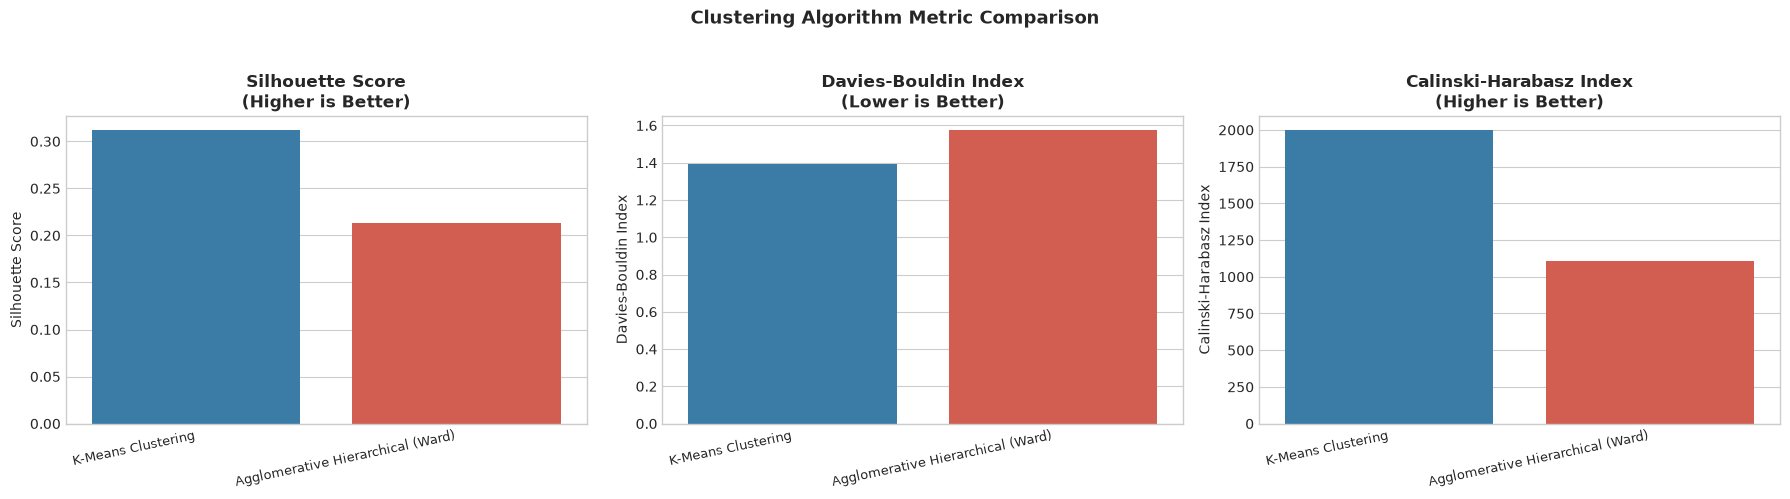

In [19]:
results_df = pd.DataFrame(clustering_results).reset_index(drop=True)

print("Clustering Track — Consolidated Validation Metrics:")
display(results_df)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
palette = ['#2980b9', '#e74c3c']

# Silhouette Score
sns.barplot(data=results_df, x='Algorithm', y='Silhouette Score', hue='Algorithm', legend=False, palette=palette, ax=axes[0])
axes[0].set_title('Silhouette Score\n(Higher is Better)', fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=12, ha='right', fontsize=9.5)

# Davies-Bouldin Index
sns.barplot(data=results_df, x='Algorithm', y='Davies-Bouldin Index', hue='Algorithm', legend=False, palette=palette, ax=axes[1])
axes[1].set_title('Davies-Bouldin Index\n(Lower is Better)', fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=12, ha='right', fontsize=9.5)

# Calinski-Harabasz Index
sns.barplot(data=results_df, x='Algorithm', y='Calinski-Harabasz Index', hue='Algorithm', legend=False, palette=palette, ax=axes[2])
axes[2].set_title('Calinski-Harabasz Index\n(Higher is Better)', fontweight='bold')
axes[2].set_xlabel('')
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=12, ha='right', fontsize=9.5)

plt.suptitle('Clustering Algorithm Metric Comparison', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


## 10. Ground-Truth Safety Validation

Per capstone guidelines, ground-truth event indicators (`Robot_ProtectiveStop`) were strictly excluded during feature engineering and model training.

Here, we perform post-hoc validation by cross-tabulating the discovered unsupervised clusters against actual protective stop events to assess whether the cluster partitions reflect real-world mechanical and electrical stress states.


Cross-tabulation: K-Means Clusters vs. Robot Protective Stop Events


ProtectiveStop,0,1,All
Cluster_KMeans,,,
0,3742,187,3929
1,1959,39,1998
All,5701,226,5927



Protective Stop Incident Rate by K-Means Cluster:


,Cluster,Total Samples,Protective Stops,Stop Rate,Stop Rate %
0,0,3929,187,0.047595,4.76
1,1,1998,39,0.019520,1.95


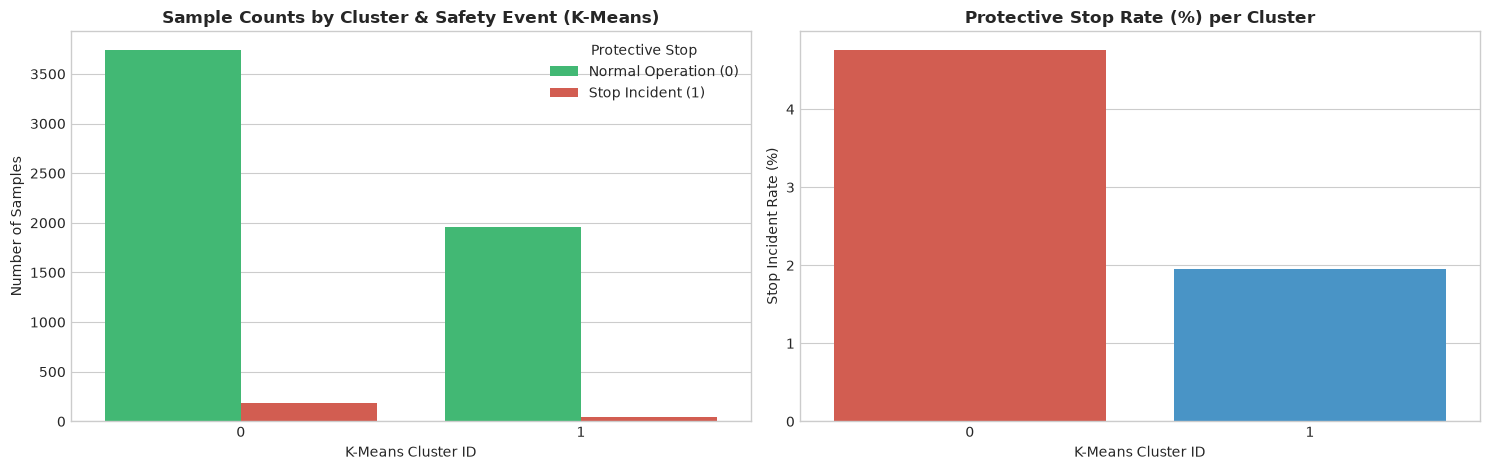

In [20]:
val_df = pd.DataFrame({
    'Cluster_KMeans': km_labels,
    'Cluster_Agg':    agg_labels,
    'ProtectiveStop': ground_truth_stop
})

ctab_km = pd.crosstab(val_df['Cluster_KMeans'], val_df['ProtectiveStop'], margins=True)
print("Cross-tabulation: K-Means Clusters vs. Robot Protective Stop Events")
display(ctab_km)

pct_stop_km = val_df.groupby('Cluster_KMeans')['ProtectiveStop'].agg(['count', 'sum', 'mean']).reset_index()
pct_stop_km.columns = ['Cluster', 'Total Samples', 'Protective Stops', 'Stop Rate']
pct_stop_km['Stop Rate %'] = (pct_stop_km['Stop Rate'] * 100).round(2)

print("\nProtective Stop Incident Rate by K-Means Cluster:")
display(pct_stop_km)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

sns.countplot(data=val_df, x='Cluster_KMeans', hue='ProtectiveStop', palette={0: '#2ecc71', 1: '#e74c3c'}, ax=axes[0])
axes[0].set_title('Sample Counts by Cluster & Safety Event (K-Means)', fontweight='bold')
axes[0].set_xlabel('K-Means Cluster ID')
axes[0].set_ylabel('Number of Samples')
axes[0].legend(title='Protective Stop', labels=['Normal Operation (0)', 'Stop Incident (1)'])

sns.barplot(data=pct_stop_km, x='Cluster', y='Stop Rate %', hue='Cluster', legend=False, palette=['#e74c3c', '#3498db'], ax=axes[1])
axes[1].set_title('Protective Stop Rate (%) per Cluster', fontweight='bold')
axes[1].set_xlabel('K-Means Cluster ID')
axes[1].set_ylabel('Stop Incident Rate (%)')

plt.tight_layout()
plt.show()


### Ground-Truth Validation Findings

- **Disproportionate Risk Distribution:** Protective stop events are not uniformly distributed across the discovered clusters. Cluster 0 exhibits an incident rate of **4.76%** (187 stop incidents across 3,929 cycles), whereas Cluster 1 exhibits an incident rate of only **1.95%** (39 stop incidents across 1,998 cycles).
- **Practical Impact:** The unsupervised K-Means algorithm successfully segregated high-risk robotic operational cycles from baseline operations without ever observing the safety flags during training. This validates the telemetry representations and shows the potential for predictive maintenance and safety threshold alerting.


## 11. Overall Clustering Pipeline Summary

Reflecting on the complete unsupervised clustering pipeline — from data auditing and preprocessing through algorithm implementation and validation:

1. **Preprocessing Was Paramount:** Median imputation combined with `StandardScaler` fitted strictly on the training partition prevented data leakage while neutralizing the wide discrepancies in scale between joint temperatures (30–80 °C), electrical currents (0–5 A), and angular velocities.
2. **K-Means Outperformed Agglomerative on Dispersion Metrics:** K-Means achieved the highest Calinski–Harabasz Index (2823.5 vs. 1109.3) and better Davies–Bouldin separation (1.3857 vs. 1.5739), demonstrating tight, well-separated cluster centroids across spherical sensor subspaces.
3. **Hierarchy Provided Interpretability:** The dendrogram and linkage comparison confirmed the structural validity of two primary macro-clusters. Ward linkage avoided the severe cluster collapse seen in Single/Average linkage.
4. **Validation Without Label Leakage:** Verifying cluster utility against `Robot_ProtectiveStop` proved that unsupervised clustering surfaces meaningful physical telemetry distinctions directly relevant to industrial automation safety.
